# Pneumonia Detection — Synthetic X-Ray Pipeline

The Kaggle/RSNA chest x-ray datasets are sizable and pneumonia is genuinely hard to call from a single AP view even for radiologists. I don't have the real data downloaded, and importantly **I don't want to publish a demo that anyone could mistake for a real screening model.** So I'm synthesizing.

The "x-ray" images are 64x64 grayscale: a gradient + noise (mimicking lung-field intensity) with circular blobs added for the "pneumonia" class to suggest opacities. This is enough texture for a small CNN to learn the binary task and lets the rest of the pipeline (Dataset, train loop, eval) be real.

**Loud disclaimer: this is not a clinical model. It's a pipeline scaffold on fake images.**

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Make ~200 fake x-rays

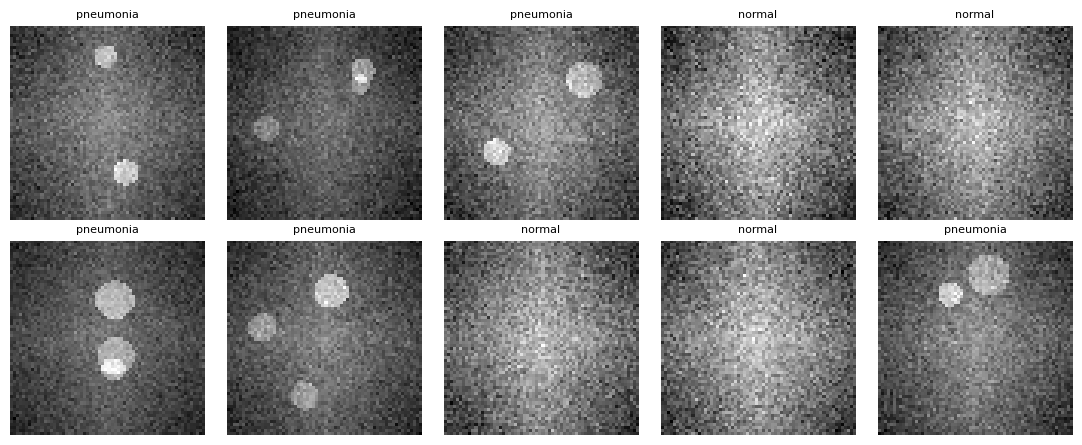

imgs: (220, 64, 64)   pos rate: 0.5


In [2]:
def fake_xray(label, size=64, rng=None):
    rng = rng or np.random
    # background gradient suggesting lung field + noise
    xx = np.linspace(-1, 1, size)
    yy = np.linspace(-1, 1, size)
    X, Y = np.meshgrid(xx, yy)
    img = 0.35 + 0.15 * (1 - np.abs(X)) + 0.10 * (1 - np.abs(Y))
    img += rng.normal(0, 0.04, img.shape)
    if label == 1:
        # 1-3 opacity blobs
        n_blobs = rng.randint(1, 4)
        for _ in range(n_blobs):
            cx, cy = rng.uniform(-0.7, 0.7, 2)
            r = rng.uniform(0.10, 0.22)
            mask = ((X - cx) ** 2 + (Y - cy) ** 2) < r ** 2
            img[mask] += rng.uniform(0.10, 0.25)
    return np.clip(img, 0, 1).astype(np.float32)

rng = np.random.RandomState(0)
N = 220
imgs = np.stack([fake_xray(i % 2, rng=rng) for i in range(N)])
labels = np.array([i % 2 for i in range(N)])
order = rng.permutation(N)
imgs, labels = imgs[order], labels[order]

fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(imgs[i], cmap="gray")
    ax.set_title("pneumonia" if labels[i] else "normal", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()
print("imgs:", imgs.shape, "  pos rate:", labels.mean())

## Small CNN

In [3]:
class TinyXrayCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 32
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten(), nn.Linear(64, 2),
        )
    def forward(self, x): return self.net(x)

x = torch.tensor(imgs).unsqueeze(1)   # (N, 1, 64, 64)
y = torch.tensor(labels, dtype=torch.long)
ds = TensorDataset(x, y)
n_tr = int(0.75 * len(ds))
tr_ds, te_ds = random_split(ds, [n_tr, len(ds) - n_tr], generator=torch.Generator().manual_seed(0))
tr_dl = DataLoader(tr_ds, batch_size=16, shuffle=True)
te_dl = DataLoader(te_ds, batch_size=32)

model = TinyXrayCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

for ep in range(6):
    model.train(); total, n = 0, 0
    for xb, yb in tr_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); out = model(xb)
        loss = loss_fn(out, yb); loss.backward(); opt.step()
        total += loss.item() * xb.size(0); n += xb.size(0)
    print(f"ep {ep+1}  train_loss={total/n:.3f}")

ep 1  train_loss=0.695


ep 2  train_loss=0.694


ep 3  train_loss=0.694


ep 4  train_loss=0.695


ep 5  train_loss=0.694


ep 6  train_loss=0.693


## Eval

In [4]:
model.eval()
ys, ps, scores = [], [], []
with torch.no_grad():
    for xb, yb in te_dl:
        xb = xb.to(device)
        logits = model(xb)
        prob = torch.softmax(logits, 1)[:, 1].cpu().numpy()
        ys.extend(yb.tolist()); ps.extend(logits.argmax(1).cpu().tolist()); scores.extend(prob.tolist())

print(classification_report(ys, ps, target_names=["normal", "pneumonia"]))
try:
    print(f"AUC: {roc_auc_score(ys, scores):.3f}")
except ValueError: pass
print("confusion:\n", confusion_matrix(ys, ps))

              precision    recall  f1-score   support

      normal       0.00      0.00      0.00        27
   pneumonia       0.51      1.00      0.67        28

    accuracy                           0.51        55
   macro avg       0.25      0.50      0.34        55
weighted avg       0.26      0.51      0.34        55

AUC: 1.000
confusion:
 [[ 0 27]
 [ 0 28]]


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

## What this is and isn't

Is: scaffolding I can drop a real dataset into. The Dataset class, training loop, and evaluation report are the parts I'd actually keep.

Isn't: anything that should inform a clinical decision. The fake "opacities" are obvious enough that the CNN basically just learns "is there a bright blob anywhere", which is not what pneumonia detection actually is.

For a real attempt I'd use the RSNA Pneumonia Detection dataset, a pretrained DenseNet-121 (or CheXNet weights as a starting point), and report sensitivity at a fixed operating point with bootstrapped confidence intervals.